# 8. The reverse sweep

A swept terminal does not always go to the left. The jim family and the ayn
family have a tail that turns back to the right. Such a letter sweeps below the
letters **before** it. It does not sweep below the letters after it.

Notebook 7 shows the forward sweep. This notebook shows the reverse sweep only.
The geometry is the same. The direction of travel is the difference.

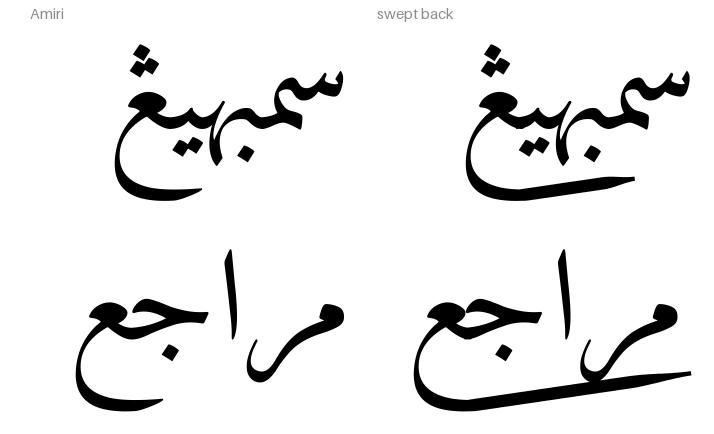

In [1]:
from textsynth import (
    Font,
    Layout,
    REVERSE_SWEEPERS,
    SWEEPERS,
    SweepShape,
    Synthesizer,
    TadakhulMerged,
    TadakhulQuantised,
    TadakhulScaled,
)
from nbutil import FONT, columns, label_font, sheet

NG = "سمبهيڠ"  # Jawi. The word ends in ng.
AYN = "مراجع"  # The word ends in ain.
layout = Layout(size=130, padding=22, supersample=2)


def swept(text, length=4, rule=TadakhulMerged, **kw):
    """Draw the text with a reverse sweep on each letter that takes one."""
    glyph_rule = rule(letters="", reverse_letters=REVERSE_SWEEPERS, length=length, **kw)
    return Synthesizer(font=FONT, layout=layout, glyph_rules=[glyph_rule])(text)


columns(
    [
        ("", Synthesizer(font=FONT, layout=layout)(NG), swept(NG)),
        ("", Synthesizer(font=FONT, layout=layout)(AYN), swept(AYN)),
    ],
    headings=("Amiri", "swept back"),
    gutter=20,
)

## Put the letters in `reverse_letters`

`letters` holds the letters that sweep forward. `reverse_letters` holds the
letters that sweep back. The default of `reverse_letters` is empty, thus a rule
that does not ask for a reverse sweep does not get one.

`REVERSE_SWEEPERS` is the set for Amiri.

In [2]:
print("forward set:", " ".join(SWEEPERS))
print("reverse set:", " ".join(REVERSE_SWEEPERS))

forward set: و ر ز ژ ۏ ؤ ڑ ۆ
reverse set: ج ح خ چ ع غ ڠ ے


## The two sets share no letter

A terminal goes one way only. Thus a letter sweeps one way only. The test is
the same test in the two directions: `cut_terminal` finds the extreme point in
the direction of travel, then it walks the two edges back and asks that they
stay parallel.

A bowl-final letter such as noon or final ya fails in the two directions. The
outside of a curve is not a free end.

In [3]:
from textsynth.shaping import shape as shape_text
from textsynth.sweeps import SweptGlyph, free_after

font = Font(FONT)
ALPHABET = "ابتثجحخدذرزسشصضطظعغفقكلمنهوىءةپچژگکیڤڠڽݢۏھڭؤڑۆے"


def sample(letter):
    """Put the letter at the end of a word, with letters on the two sides."""
    return "سم" + letter + " ادب"


def sweeps(letter, direction):
    """Tell if the letter has a terminal that goes this way."""
    text = sample(letter)
    glyphs = [g for g in shape_text(text, font) if g.cluster == 2]
    if not glyphs or not free_after(text, 2):
        return False
    swept_glyph = SweptGlyph(font=font, glyph=glyphs[0].name, shape=SweepShape(), direction=direction)
    return swept_glyph.end is not None


letters = [c for c in dict.fromkeys(ALPHABET) if font.covers(c)]
forward = [c for c in letters if sweeps(c, -1)]
reverse = [c for c in letters if sweeps(c, +1)]

print("forward:", " ".join(forward))
print("reverse:", " ".join(reverse))
print("both:   ", " ".join(set(forward) & set(reverse)) or "none")
print("neither:", " ".join(c for c in letters if c not in forward and c not in reverse))

forward: ر ز و ژ ۏ ؤ ڑ ۆ
reverse: ج ح خ ع غ چ ڠ ے
both:    none
neither: ا ب ت ث د ذ س ش ص ض ط ظ ف ق ك ل م ن ه ى ء ة پ گ ک ی ڤ ڽ ݢ ھ ڭ


## Each letter of the reverse set

The left column is the plain word. The right column has the sweep.

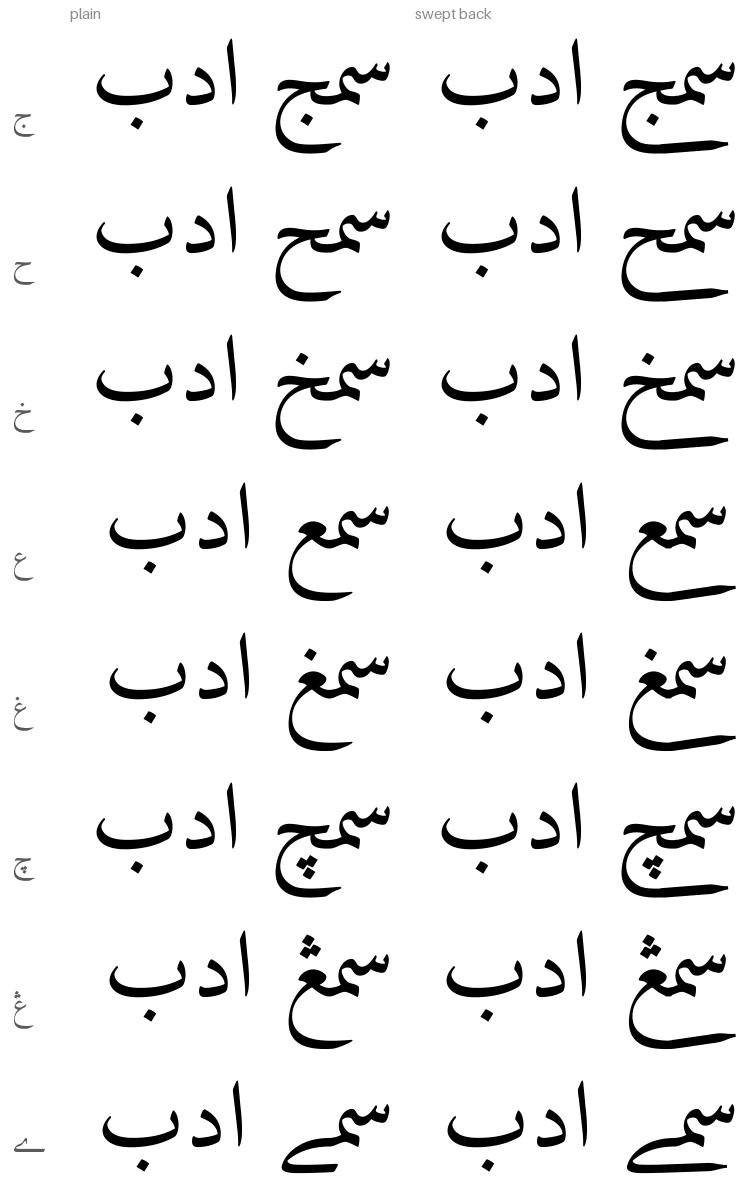

In [4]:
small = Layout(size=95, padding=14, supersample=2)
rows = []
for letter in reverse:
    text = sample(letter)
    rule = TadakhulMerged(letters="", reverse_letters=letter, length=2)
    rows.append((
        letter,
        Synthesizer(font=FONT, layout=small)(text),
        Synthesizer(font=FONT, layout=small, glyph_rules=[rule])(text),
    ))

columns(rows, headings=("plain", "swept back"), gutter=60, font=label_font(30, arabic=True))

## The length counts the letters before

`length=2` makes the letter as long as the two letters before it. The forward
rule counts the letters after. The reverse rule counts the other way.

The sweep goes below the word. Thus the image does not get wider.

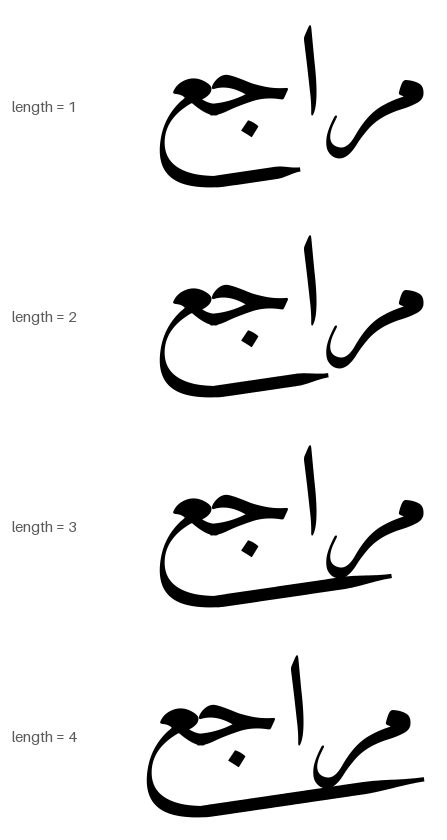

In [5]:
sheet([(f"length = {n}", swept(AYN, length=n)) for n in range(1, 5)], gutter=120)

## The nib does not mirror with the stroke

A scribe keeps the pen at one angle for the full page. A tail that turns back
does not turn the pen. Thus the code keeps two values apart:

- `direction` gives the way the stroke goes;
- `mirror` gives the way the script goes.

A left-to-right script is the mirror image of the hand, and only then does the
nib mirror.

In [6]:
import math
from textsynth.outlines import body_path, cut_terminal, glyph_contours, measure_end

glyph_set = font.ttfont().getGlyphSet()
sweep_shape = SweepShape()


def terminal_of(letter, direction):
    """Cut the terminal of the final form of the letter and measure it."""
    name = [g for g in shape_text("سم" + letter, font) if g.cluster == 2][0].name
    path = body_path(glyph_contours(glyph_set, name))
    cut = cut_terminal(path, sweep_shape.cut_back * font.upem, direction=direction)
    return measure_end(cut, direction=direction, max_height=-sweep_shape.descender * font.upem)


for label, letter, direction in (("waw, forward", "و", -1), ("ain, reverse", "ع", +1)):
    end = terminal_of(letter, direction)
    nib = sweep_shape.pen(end, font.upem, mirror=False)
    print(f"{label:>13}: stroke {math.degrees(end.heading):4.0f} deg, nib {math.degrees(nib.angle):4.0f} deg")

end = terminal_of("ع", +1)
mirrored = sweep_shape.pen(end, font.upem, mirror=True)
print(f"\nthe same ain in a left-to-right script: nib {math.degrees(mirrored.angle):.0f} deg")

 waw, forward: stroke -155 deg, nib  135 deg
 ain, reverse: stroke    4 deg, nib  135 deg

the same ain in a left-to-right script: nib 45 deg

## The three rules take a reverse sweep

`TadakhulMerged`, `TadakhulQuantised`, and `TadakhulScaled` each accept
`reverse_letters`. The cost of each rule does not change. Notebook 7 gives the
table.

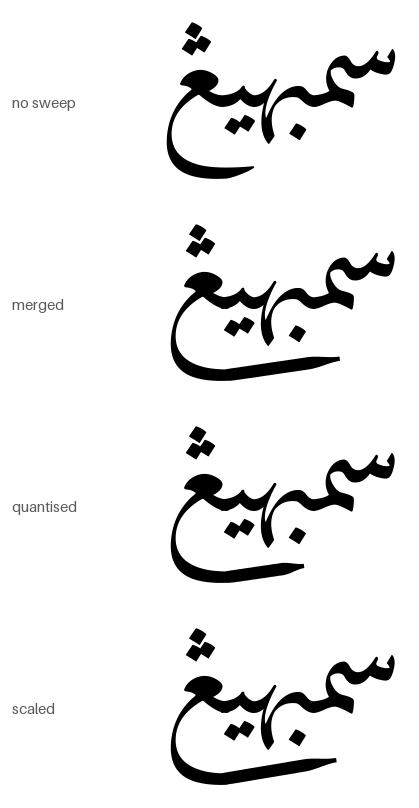

In [7]:
rows = [("no sweep", Synthesizer(font=FONT, layout=layout)(NG))]
for name, rule in (("merged", TadakhulMerged), ("quantised", TadakhulQuantised), ("scaled", TadakhulScaled)):
    rows.append((name, swept(NG, rule=rule)))

sheet(rows, gutter=140)

## The geometry parameters do the same work

`SweepShape` gives the path as a curvature profile. The profile starts at the
curvature of the cut. `belly` sets the lowest point. `lift` sets the width at
the tip. The parameters act on a reverse sweep as they act on a forward
sweep.

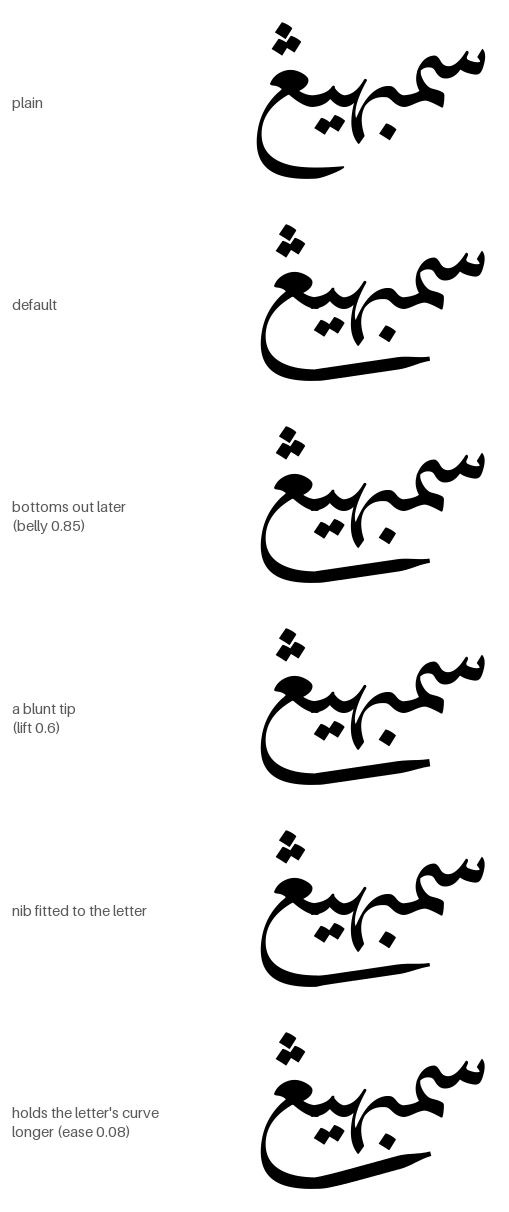

In [8]:
rows = [("plain", Synthesizer(font=FONT, layout=layout)(NG))]
for name, geometry in (
    ("default", SweepShape()),
    ("bottoms out later\n(belly 0.85)", SweepShape(belly=0.85)),
    ("a blunt tip\n(lift 0.6)", SweepShape(lift=0.6)),
    ("nib fitted to the letter", SweepShape(nib_angle=None)),
    ("holds the letter's curve\nlonger (ease 0.08)", SweepShape(ease=0.08)),
):
    rows.append((name, swept(NG, shape=geometry)))

sheet(rows, gutter=230)

## Limits

- A letter sweeps back only where it ends its stroke. A letter in the middle of
  a word has a join there. `free_after` gives this test, and it gives the same
  test to the two directions.
- The reverse set is the set for Amiri. Another face has a different set: in
  Scheherazade New the jim family has no free terminal, and bari ye has one.
  Run the survey above for another face.
- A reverse sweep goes below the letters before it. Thus it can meet a forward
  sweep that comes from a letter after it. The two strokes then cross.
- A reverse sweep does not lift the letters above it. The nearest of those
  letters joins to the sweeping letter, and a lift would pull it off the join.
  `lift` acts on a forward sweep only.